<a href="https://colab.research.google.com/github/Manawariqbal/Data-Analysis-Projects/blob/main/Weather_comparision_projects.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
3. Weather Comparison (weather_data.csv, 3 cities × 2 years)
Question: “How do Pune, Delhi, and Chennai differ in climate?”

1:Fill the missing temperatures, ideally by city median.
2:Extract the month and season from the date.
3:Plot monthly average temperature per city in one line chart.
4:Show total rainfall by month in a bar chart.
5:Compare the temperature distributions in a violin or box plot.
6:Plot humidity against rainfall in a scatter plot.
7:Write a conclusion on which city has the most extreme weather.
"""

In [2]:
#import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('weather_data.csv')
df.head()
df.isna().sum()

,0
date,0
city,0
temp_c,30
humidity_pct,0
rainfall_mm,0
wind_kmh,0


In [5]:
#1:Fill the missing temperatures, ideally by city median.
df["temp_c"] = df["temp_c"].fillna(

    df.groupby("city")["temp_c"].transform("median")

)

In [6]:
df.isna().sum()

,0
date,0
city,0
temp_c,0
humidity_pct,0
rainfall_mm,0
wind_kmh,0


In [9]:
#Task Extract the month and season from the date.
#create two columns date and month
#create season columns
#12,1,2 then winter
#3 4 5 Summer
#month 6,7,8,9 monsoon, by default post-monsoon

df["date"]=pd.to_datetime(df["date"])
df["month"]=df["date"].dt.month
df["season"]=np.select(
    [df["month"].isin([12,1,2]),
     df["month"].isin([3,4,5]),
     df["month"].isin([6,7,8,9])
    ],
    ["winter","summer","monsoon"],
    default="post-monsoon"
)


In [10]:
df

,date,city,temp_c,humidity_pct,rainfall_mm,wind_kmh,month,season
0,2024-01-01,Pune,20.0,72.0,0.0,17.0,1,winter
1,2024-01-02,Pune,18.2,62.0,0.0,8.5,1,winter
2,2024-01-03,Pune,19.4,59.0,0.0,10.3,1,winter
3,2024-01-04,Pune,21.1,49.0,0.0,19.5,1,winter
4,2024-01-05,Pune,19.3,59.0,0.0,13.2,1,winter
...,...,...,...,...,...,...,...,...
2188,2025-12-27,Chennai,26.3,54.0,0.0,19.7,12,winter
2189,2025-12-28,Chennai,27.1,47.0,0.0,10.9,12,winter
2190,2025-12-29,Chennai,25.1,62.0,0.0,9.4,12,winter
2191,2025-12-30,Chennai,25.4,62.0,0.0,11.0,12,winter


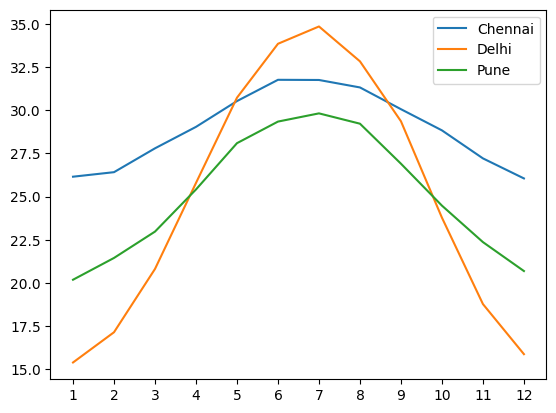

In [14]:
#Task 3:Plot monthly average temperature per city in one line chart.
monthly_temp=df.groupby(["month","city"])["temp_c"].mean().unstack()
monthly_temp

for city in monthly_temp.columns:
  plt.plot(monthly_temp.index,monthly_temp[city],label=city)
plt.xticks(range(1,13))
plt.legend()
plt.show()
#

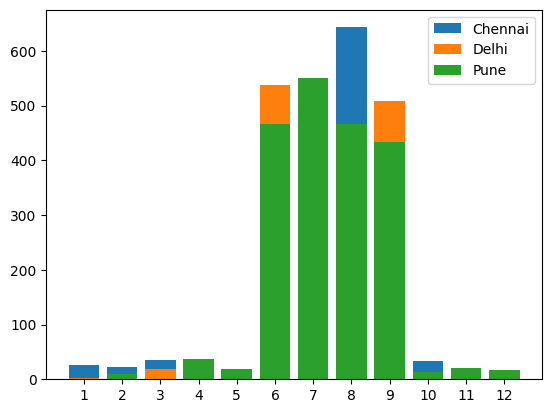

In [20]:
#Task 4:Show total rainfall by month in a bar chart.
df
monthly_rain=df.groupby(["month","city"])["rainfall_mm"].sum().unstack()
monthly_rain
for city in monthly_rain.columns:
  plt.bar(monthly_rain.index,monthly_rain[city],label=city)
plt.xticks(range(1,13))
plt.legend()
plt.show()
#

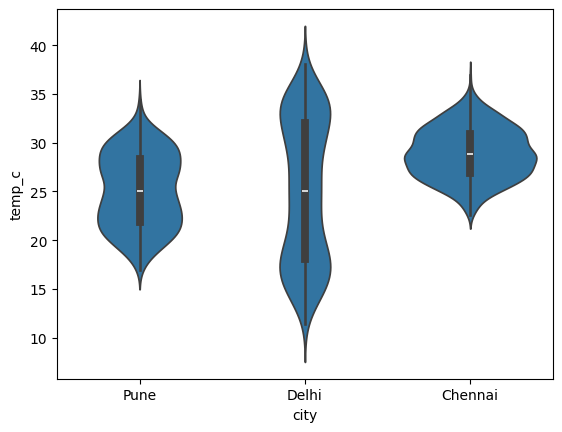

In [21]:
#Task 5:Compare the temperature distributions in a violin or box plot.

sns.violinplot(data=df,x="city",y="temp_c")
plt.show()
#

In [25]:
df

,date,city,temp_c,humidity_pct,rainfall_mm,wind_kmh,month,season
0,2024-01-01,Pune,20.0,72.0,0.0,17.0,1,winter
1,2024-01-02,Pune,18.2,62.0,0.0,8.5,1,winter
2,2024-01-03,Pune,19.4,59.0,0.0,10.3,1,winter
3,2024-01-04,Pune,21.1,49.0,0.0,19.5,1,winter
4,2024-01-05,Pune,19.3,59.0,0.0,13.2,1,winter
...,...,...,...,...,...,...,...,...
2188,2025-12-27,Chennai,26.3,54.0,0.0,19.7,12,winter
2189,2025-12-28,Chennai,27.1,47.0,0.0,10.9,12,winter
2190,2025-12-29,Chennai,25.1,62.0,0.0,9.4,12,winter
2191,2025-12-30,Chennai,25.4,62.0,0.0,11.0,12,winter


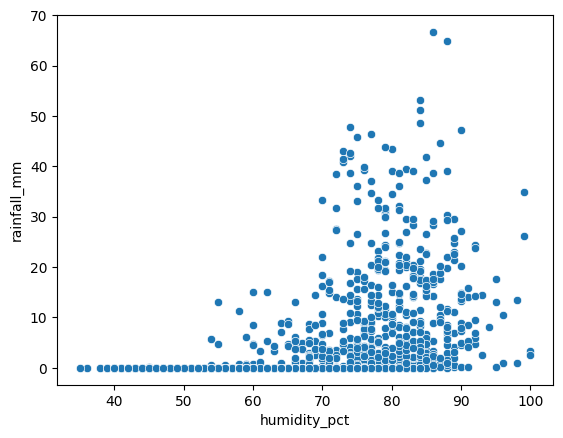

In [26]:
#Task 6:Plot humidity against rainfall in a scatter plot.
sns.scatterplot(data=df,x="humidity_pct",y="rainfall_mm")
plt.show()
#

In [27]:
# 7: Write a conclusion on which city has the most extreme weather.

conclusion = """
Conclusion: Delhi has the most extreme weather among the three cities.

Reasoning:
1. Temperature Extremes:
   - Delhi shows the widest range of temperature distribution in the violin plot (ranging from below 10°C to above 40°C).
   - From the monthly average line chart, Delhi has the coldest winters (averaging ~15°C in January and December) and the hottest summers (averaging ~35°C in June/July).
   - By contrast, Chennai stays consistently warm throughout the year (~26°C to ~32°C), and Pune has a moderate climate with less extreme highs and lows.

2. Rainfall and Humidity:
   - While Chennai and Pune experience heavy monsoon spells, Delhi exhibits sharp contrasts of dry seasons and sudden high-rainfall monsoon months (June-September), adding to its extreme climatic pattern.
"""
print(conclusion)


Conclusion: Delhi has the most extreme weather among the three cities.

Reasoning:
1. Temperature Extremes:
   - Delhi shows the widest range of temperature distribution in the violin plot (ranging from below 10°C to above 40°C).
   - From the monthly average line chart, Delhi has the coldest winters (averaging ~15°C in January and December) and the hottest summers (averaging ~35°C in June/July).
   - By contrast, Chennai stays consistently warm throughout the year (~26°C to ~32°C), and Pune has a moderate climate with less extreme highs and lows.

2. Rainfall and Humidity:
   - While Chennai and Pune experience heavy monsoon spells, Delhi exhibits sharp contrasts of dry seasons and sudden high-rainfall monsoon months (June-September), adding to its extreme climatic pattern.

